<span style="font-weight: bold; font-size: 50px; color: rgb(34, 101, 160);"> Optical properties extraction : </span> <br>
<span style="font-size: 35px">
Extraction $n(\nu) - \kappa(\nu)$ and $\alpha(\nu)$ from first echo in reflection mode
</span>

# <span style="font-size: 35px"> <strong>Step 1:</strong> Creating and saving ROI for all samples

In [105]:
import sys 
import os

from Sources.LoadData_tprj import *
from Sources import process_list

file_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"
# file_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"

keys = get_all_available_measurements(file_path)
for key in keys: print(key)

14_composite_20-percent_poro
13_Oxyde-2_raw_no_porogene
12_Oxyde-2_no_porogene_20-percent_poro
11_Oxyde-7_porogene_pression-P2_with_porogene
1_Oxyde-1_no_porogene_0-percent_porosity
10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene
9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene
8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene
7_Oxyde-5_raw_no_porogene
6_Oxyde-5_no_porogene_0-percent_poro
5_Oxyde-4_raw_no_porogene
3_Oxyde-3_raw_no_porogene
4_Oxyde-4_no_porogene_0-percent_poro
3_Oxyde-3_raw_no_porogene_no_focus
2_Oxyde-3_no_porogene_0-percent_porosity
1_Oxyde-1_no_porogene_0-percent_porosity_old_holder


In [ ]:
import h5py

file_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj" #r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CTTC_ceramics_CarnotArts_AAPG.tprj"

save_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files"
# save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files"

save = False

with h5py.File(f'{file_path}', 'r') as file:
    measurements = file['TerapulseDocument']['Measurements']

    # Only keeping the last reference as the overall reference data
    ref_keys = list(measurements['Ref Data'].keys())[:]
    refs = []
    for ref_key in ref_keys:
        ref = pd.DataFrame(measurements['Ref Data'][ref_key]['sample']['ydata'][:])
        refs.append(measurements['Ref Data'][ref_key]['sample']['ydata'][:].T[0])      
    refs = pd.DataFrame(refs)

    time_axis = pd.DataFrame(measurements['Ref Data'][ref_key]['sample']['xdata'][:])

    print(f"CSV file will be saved as: {save_path}")
    
    if save:
        refs.to_csv(save_path+r'\references.csv', index=False, header=False)
        time_axis.T.to_csv(save_path+r'\time_axis.csv', index=False, header=False)

In [ ]:
from tqdm import tqdm

x_shape_list = []
y_shape_list = []
file_list = []

save_path = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files"
# save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Raw_data\THz\Ceramics\CSV_files"

save = False

for idx in tqdm(range(len(keys))):
    name = f"{keys[idx]}.csv"

    path = os.path.join(save_path, name)
    print(f"CSV file will be saved as: {path}")

    measurement = HDF5Handler(file_path).get_data_df(keys[idx], 'Image Data')

    X,Y,x,y,nx,ny,pattern_x_arranged,pattern_y_arranged = process_list.spacial_correction(measurement[0],measurement[1])
    data_Y_arranged = process_list.data_correction(measurement, X, Y)
    data_X_arranged = process_list.ArrangedData_Xconstant(pattern_x_arranged, pattern_y_arranged, data_Y_arranged)

    x_shape_list.append(x.shape)
    y_shape_list.append(y.shape)
    file_list.append(path)
    
    if save :
        data_X_arranged.T.to_csv(path, index=False, header=False)

In [ ]:
import numpy as np

prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

np.save(fr"{prefix_path}/x_shape_list", x_shape_list)
np.save(fr"{prefix_path}/y_shape_list", y_shape_list)
np.save(fr"{prefix_path}/file_list", file_list)

In [ ]:
from tqdm import tqdm

prefix_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

save_path = r"F:\GeorgiaTech\Programming\Ceramic_processing\Data"
# save_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"
save = True

ROI_list = []

X_ROI = 15
Y_ROI = 15

for idx in tqdm(range(len(file_list))):
    # loadi into numpy array
    signal_array = np.loadtxt(file_list[idx], delimiter=',')
    signal_array = signal_array[:, :].T

    # Show matrix size
    print(file_list[idx])
    print("array shape:", signal_array.shape)
    print(x_shape_list[idx], x_shape_list[idx][0]*x_shape_list[idx][1])
    print(y_shape_list[idx], y_shape_list[idx][0]*y_shape_list[idx][1])

    datacube = signal_array.reshape(x_shape_list[idx][1], x_shape_list[idx][0], 2048) # If using filtered signal
    # Check size
    print("Final datacube shape (x,y,time):", datacube.shape)



    ROI = datacube[datacube.shape[0]//2-X_ROI:datacube.shape[0]//2+X_ROI,
                datacube.shape[1]//2-Y_ROI:datacube.shape[1]//2+Y_ROI,
                :]

    ROI_list.append(ROI)

ROI_arr = np.array(ROI_list)
if save :
    np.save(rf"{save_path}/ROI_arr", ROI_arr)

# <span style="font-size: 35px"> <strong>Step 2:</strong> Loading existing ROI of THz Datacube

In [24]:
import numpy as np
import pandas as pd

prefix_path = r"D:\Documents\CNRS_Georgia_Tech\Work\Ceramic_processing\Data"
# prefix_path = r"\\10.29.58.4\umi2958-users\GTL\hcherid\Windows\Programming_Data\Ceramic_processing"

x_shape_list = np.load(fr"{prefix_path}/x_shape_list.npy")
y_shape_list = np.load(fr"{prefix_path}/y_shape_list.npy")
file_list = np.load(fr"{prefix_path}/file_list.npy")

ROI_arr = np.load(fr"{prefix_path}/ROI_arr.npy")

path_to_refs = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\references.csv"
references = pd.read_csv(path_to_refs, header = None).to_numpy()

path_to_timeaxis = r"F:\GeorgiaTech\THz_raw_data\Ceramics\CSV_files\time_axis.csv"
time_axis = pd.read_csv(path_to_timeaxis, header = None).to_numpy().T


# <span style="font-size: 35px"> <strong>Study 1:</strong> A-scan visualization

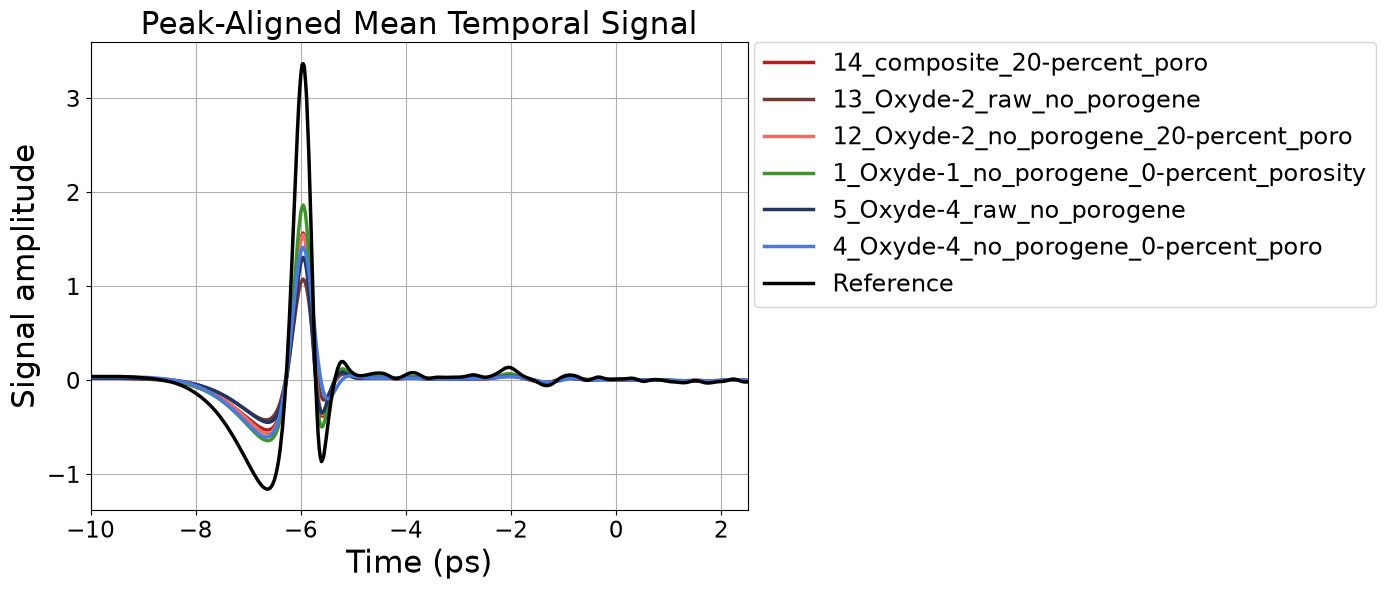

In [124]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

dt_ps = 0.020464 

n_samples = ROI_arr.shape[0]
T = ROI_arr.shape[-1]

colors = [
    "#ba1b1b",  # 14_composite_20-percent_poro 0
    "#723834",  # 13_Oxyde-2_raw_no_porogene 1
    "#e67068",  # 12_Oxyde-2_no_porogene_20-percent_poro 2
    "#58190C",  # 11_Oxyde-7_porogene_pression-P2_with_porogene 3
    "#40942B",  # 1_Oxyde-1_no_porogene_0-percent_porosity 4
    "#9d2b14",  # 10_Oxyde-7_porogene_pression-P2_20-percent_poro_without_porogene 5
    "#8c2f00",  # 9_Oxyde-6_raw_porogene_pression-P1_20-percent_poro_with_porogene 6
    "#ff5500",  # 8_Oxyde-6_porogene_pression-P1_20-percent_poro_without_porogene 7
    "#202245",  # 7_Oxyde-5_raw_no_porogene 8
    "#474c99",  # 6_Oxyde-5_no_porogene_0-percent_poro 9
    "#213561",  # 5_Oxyde-4_raw_no_porogene 10
    "#4F5B76",  # 3_Oxyde-3_raw_no_porogene 11
    "#4b7ade",  # 4_Oxyde-4_no_porogene_0-percent_poro 12
    "#843c39",  # 3_Oxyde-3_raw_no_porogene_no_focus 13
    "#A0B9F0",  # 2_Oxyde-3_no_porogene_0-percent_porosity 14
    "#3182bd",  # 1_Oxyde-1_no_porogene_0-percent_porosity_old_holder 15
]


# sample_list = [4]
# labels = ["Oxyde 1"]
# sample_list = [4, 9, 12, 14] #  Heated samples influence of diameter and height
# labels = ['Oxyde 1', 'Oxyde 5', 'Oxyde 4', 'Oxyde 3']
# sample_list = [4,0, 2, 5, 7] # Heated internal porosity and porogene changes
sample_list = [0, 1, 2, 4, 10, 12] # Heated vs raw
labels = []


ref_mean = np.mean(references, axis=0)
ref_peak = np.argmax(ref_mean)

mean_signals = []
for i in sample_list:
    labels.append(file_list[i].split("\\")[-1].rstrip(".csv"))
    signals = ROI_arr[i].reshape(-1, T)

    signals_aligned = []
    cpt = 0

    sample_max_peak = np.max(signals)
    
    for signal in signals : 
        shift = sample_max_peak - np.argmax(signal)
        max = np.max(signal)

        if max > 0.8*sample_max_peak and max < 1.2*sample_max_peak:
            signals_aligned.append(np.roll(signal, shift))
    
        cpt +=1
    signals_aligned = np.array(signals_aligned)
    mean_signal = signals_aligned.mean(axis=0)
    shift = ref_peak - np.argmax(mean_signal)

    mean_signals.append( np.roll(mean_signal, shift, axis=0) )

mean_signals = np.array(mean_signals)

t = np.arange(T)*dt_ps

plt.figure(figsize=(14, 6))

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]

    plt.plot(time_axis, mean_signals[cpt], color=color, linewidth=2.5, label=labels[cpt])
    
    cpt +=1

plt.plot(time_axis, ref_mean, color = 'black',  linewidth=2.5, label='Reference')


FONT_SIZE=22
plt.title("Peak-Aligned Mean Temporal Signal", fontsize=FONT_SIZE)
plt.xlabel("Time (ps)", fontsize=FONT_SIZE)
plt.ylabel("Signal amplitude", fontsize=FONT_SIZE)
plt.legend(fontsize=FONT_SIZE*0.8, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
plt.tick_params(axis='x', which='major', labelsize=FONT_SIZE*0.75)
plt.tick_params(axis='y', which='major', labelsize=FONT_SIZE*0.75)
plt.tight_layout()
# plt.xlim([time_axis.min(), time_axis.max()])
plt.xlim([-10,2.5])
plt.grid()
plt.show()

# <span style="font-size: 35px"> <strong>Study 2:</strong> Optical properties extraction

In this study, we extract the **refractive index** $n(\nu)$ and **absorption coefficient** $\alpha(\nu)$ of each sample directly from the **first air/sample reflection echo**, without using a second (back-surface) echo. This "single-echo reflection" configuration is valid because the samples are thick enough that the back-surface reflection falls outside the time-domain acquisition window and does not interfere with the first echo.

**Procedure:**

1. **Reference measurement**: a flat metal mirror is placed in the exact same plane as the sample surface, and its time-domain reflected field $E_{ref}(t)$ is recorded. The mirror's Fresnel reflection coefficient is taken as $\rho_{ref} = -1$.

2. **Sample measurement**: the reflected field from the sample $E_{sam}(t)$ is recorded and time-windowed before any second (back-surface) echo arrives.

3. **Fourier transform**: both signals are transformed to the frequency domain, and the complex transfer function is computed:

$$\tilde{T}_b(\nu) = \frac{\tilde{E}_{sam}(\nu)}{\tilde{E}_{ref}(\nu)} = -\rho_{1,2}(\nu)$$

Because there is no propagation term (no sample thickness involved in this configuration), no phase unwrapping is required — the phase of $\tilde{T}_b(\nu)$ stays bounded.

4. **Inversion**: writing $\tilde{T}_b(\nu) = x(\nu) + i\,y(\nu)$, the complex refractive index $\tilde{n}(\nu) = n(\nu) + i\kappa(\nu)$ is obtained algebraically by inverting the Fresnel reflection formula $\rho_{1,2} = \frac{1-\tilde n}{1+\tilde n}$:

$$n(\nu) = \frac{1 - x^2 - y^2}{(1-x)^2 + y^2}, \qquad \kappa(\nu) = \frac{2y}{(1-x)^2 + y^2}$$

5. **Absorption coefficient**: from the extinction coefficient $\kappa(\nu)$, the absorption coefficient is computed as:

$$\alpha(\nu) = \frac{4\pi\nu\,\kappa(\nu)}{c}$$

This configuration is particularly useful for **highly absorbing or thick samples**, since it does not rely on radiation propagating through the bulk of the material, and the achievable dynamic range is limited only by scan-to-scan reproducibility rather than the spectrometer's dynamic range.

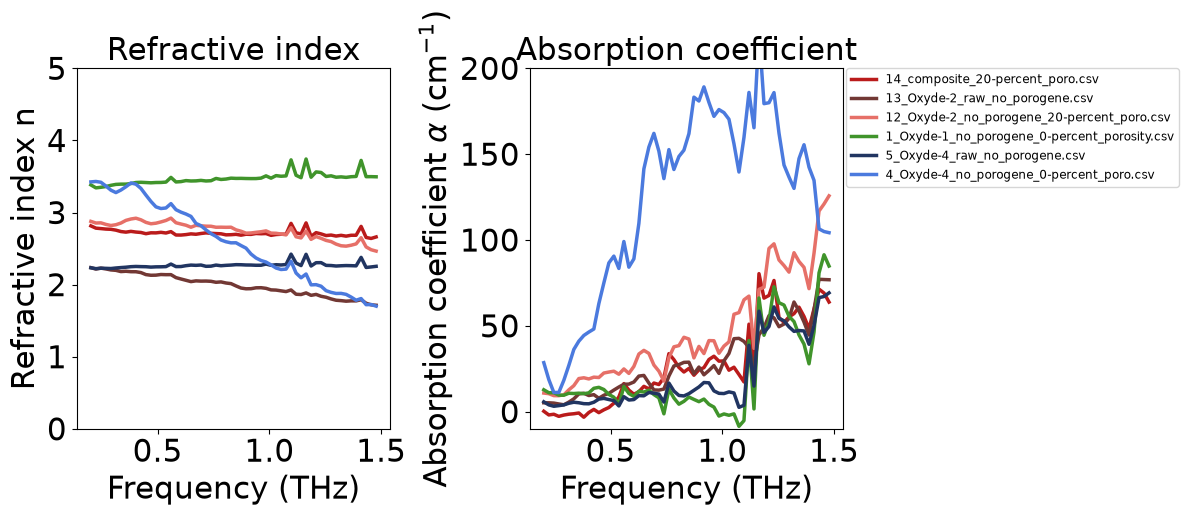

[1.9651503  2.22704437 2.38406256 2.62144193 2.87071541 3.03063348
 3.22902968 3.38979869 3.4247837  3.43083819 3.41988602 3.36801952
 3.31015649 3.27681742 3.31187125 3.3576813  3.40984936 3.39357204
 3.33448705 3.24216673 3.15376043 3.07878463 3.05543506 3.06319866
 3.12361337 3.03973197 3.00537476 2.9793612  2.94641756 2.84878067
 2.81705208 2.75911427 2.70718399 2.66919504 2.61913252 2.59470602
 2.57962681 2.58059597 2.54219451 2.50614671 2.42439008 2.36927774
 2.33485841 2.31316143 2.273562   2.23042743 2.20981375 2.21534036
 2.32439701 2.16095991 2.09474358 2.14720937 1.9969526  1.9996976
 1.97816713 1.91607836 1.89265834 1.87737178 1.87853471 1.86499736
 1.82743089 1.78372735 1.80677466 1.7217843  1.72439623 1.70151638]
[array([ 464.72825909,  295.5537412 ,  -59.24793354,  129.66257226,
         66.93632166, -107.74367194, -519.26243185, -139.95599871,
         24.19810247, -190.60723041, -150.66044782, -274.54247304,
       -197.97959156, -148.76773643, -121.77288314,  -77.4747

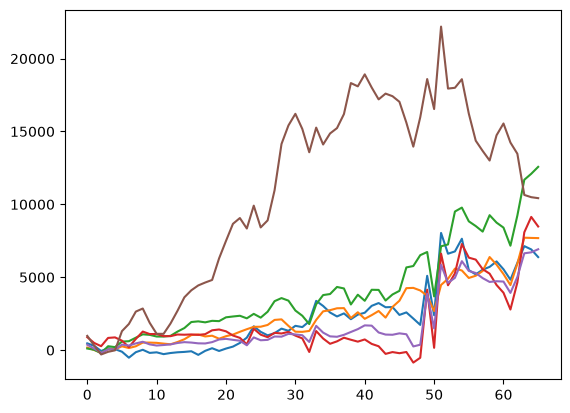

In [127]:
from scipy.fft import fft, fftfreq

yf_ref = fft(ref_mean)

c = 3e8

dt = (time_axis[1] - time_axis[0]) * 1e-12
freq = np.fft.fftfreq(len(time_axis), d=dt)

CUTOFF_FREQ = 1.5e12  # Hz, only frequencies below this (and > 0) are kept

# Build the positive-frequency, sub-cutoff mask once
pos_mask = (freq > 0) & (freq <= CUTOFF_FREQ)
freq = freq[pos_mask]  # freq is now restricted to (0, CUTOFF_FREQ]

n_list = []
k_list = []
alpha_list = []

cpt = 0
for i in sample_list:
    color = colors[i]
    label = file_list[i].split("\\")[-1]

    # FFT of the sample signal
    yf = fft(mean_signals[cpt])

    Tb = (yf / yf_ref)[pos_mask]   # <-- restrict to positive freqs / cutoff

    x = np.real(Tb)
    y = -np.imag(Tb)

    denom = (1 - x)**2 + y**2
    n = (1 - x**2 - y**2) / denom
    k = (2 * y) / denom

    alpha = (4 * np.pi * freq * k) / c  # vectorized, freq already masked

    n_list.append(n)
    k_list.append(k)
    alpha_list.append(alpha)

    cpt += 1

def plot_optical_properties(freq, n_list, alpha_list, sample_list, file_list, colors,
                             f_min=0.2e12, f_max=3.0e12, linewidth=2.5,  FONT_SIZE=14):
    """
    Plot refractive index and absorption coefficient vs frequency
    for each sample in sample_list.

    Parameters
    ----------
    freq : ndarray
        Frequency axis (Hz), as returned by np.fft.fftfreq.
    n_list, alpha_list : list of ndarray
        Refractive index and absorption coefficient (m^-1) per sample,
        same order as sample_list.
    sample_list : list of int
        Indices of samples plotted.
    file_list : list of str
        Full file paths/names, used to build labels.
    colors : dict or list
        Color per sample index.
    f_min, f_max : float
        Frequency range (Hz) to display (mask out noisy/negative freqs).
    FONT_SIZE : int
        Controls font size of labels, ticks, legend, and title.
    """

    mask = (freq >= f_min) & (freq <= f_max)
    freq_thz = freq[mask] * 1e-12  # convert to THz for display

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    for cpt, i in enumerate(sample_list):
        color = colors[i]
        label = file_list[i].split("\\")[-1]

        ax[0].plot(freq_thz, n_list[cpt][mask], color=color, label=label, linewidth = linewidth)
        ax[1].plot(freq_thz, alpha_list[cpt][mask] * 1e-2, color=color, label=label, linewidth = linewidth)
        # *1e-2 converts alpha from m^-1 to cm^-1, common convention in THz-TDS

    ax[0].set_xlabel("Frequency (THz)", fontsize=FONT_SIZE)
    ax[0].set_ylabel("Refractive index n", fontsize=FONT_SIZE)
    ax[0].set_title("Refractive index", fontsize=FONT_SIZE)
    ax[0].tick_params(axis='both', labelsize=FONT_SIZE)
    ax[0].set_ylim([0,5])

    ax[1].set_xlabel("Frequency (THz)", fontsize=FONT_SIZE)
    ax[1].set_ylabel(r"Absorption coefficient $\alpha$ (cm$^{-1}$)", fontsize=FONT_SIZE)
    ax[1].set_title("Absorption coefficient", fontsize=FONT_SIZE)
    ax[1].tick_params(axis='both', labelsize=FONT_SIZE)
    ax[1].set_ylim([-10,200])

    # ax[0].legend(fontsize=FONT_SIZE - 2)
    ax[1].legend(fontsize=FONT_SIZE*0.4, bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)

    fig.tight_layout()

    return fig, ax


fig, ax = plot_optical_properties(freq, n_list, alpha_list, sample_list, file_list, colors,
                                   FONT_SIZE=22)
plt.show()
print(n)
print(alpha_list)

plt.plot(np.array(alpha_list).T)